# Study 21 - New station: label-free estimator against models that need labels

Question (Edison, point 5): is there a setting where the estimator is the better choice?
Candidate: a newly commissioned sampling point with little local history and no local labels.

Protocol = study13 exactly (statistics from the first n days, scoring only afterwards, test months only).
On the SAME scored rows three competitors are added:
- **Transferred GBM / logistic (leave-one-city-out):** trained with labels from all other cities, applied to the new station.
  Uses the same first-n-day station statistics as the estimator, so the information is identical apart from the labels elsewhere.
- **Local GBM / logistic:** trained only on the labelled onset points inside the station's first n days.
  Unavailable when the warm-up holds fewer than 5 onsets or 5 non-onsets; coverage is reported.

No outcome is assumed. If the transferred GBM leads at every n, that is the finding.


In [1]:
import numpy as np, pandas as pd, math, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
np.random.seed(0)
OUT=Path("../outputs/study21_new_station"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":150,"font.size":11,"axes.grid":True,"grid.alpha":0.25,"axes.spines.top":False,"axes.spines.right":False})
STEP=6; H=4; TAU=15.0
pm=pd.read_csv("../data/openaq_regional/regional_pm25.csv"); pm["datetime"]=pd.to_datetime(pm["datetime"],utc=True)
pm["name"]=pm.station.str.split("::").str[1]; pm=pm.dropna(subset=["value"]); pm=pm[(pm.value>=0)&(pm.value<1500)]
met=pd.read_csv("../data/era5/era5_regional.csv",usecols=["datetime","station","wind_speed","blh","t2m"])
met["datetime"]=pd.to_datetime(met["datetime"],utc=True); met=met.rename(columns={"station":"name"})
yrs=pm.groupby("station")["datetime"].agg(lambda s:(s.max()-s.min()).days/365.25); pm=pm[pm.station.isin(yrs[yrs>=2].index)].copy()
print("stations",pm.station.nunique())


/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


stations 21


In [2]:
# ---- twin, metrics, helpers: copied verbatim from study4/study5 so behaviour is identical ----
K=5; LEV=[i/(K-1) for i in range(K)]; SDL=[1.0+0.5*l for l in LEV]; LOGC=0.5*math.log(2*math.pi); LGC=[-LOGC-math.log(sd) for sd in SDL]
def lgv(z): return [LGC[k]-0.5*((z-2.0*LEV[k])/SDL[k])**2 for k in range(K)]
WPM,WW,WB,WT=1.0,0.5,0.5,0.4
def twin(zpm,zw,zb,zt,wpm=None,ww=None,wb=None,wt=None):
    wpm=WPM if wpm is None else wpm; ww=WW if ww is None else ww
    wb=WB if wb is None else wb;   wt=WT if wt is None else wt
    logb=[-3*k for k in range(K)]; m=max(logb); ss=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ss) for x in logb]
    risk=np.empty(len(zpm)); ent=np.empty(len(zpm))
    for t in range(len(zpm)):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*LEV[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15; bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0: bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        for zv,w,inv in [(zpm,wpm,1),(zw,ww,-1),(zb,wb,-1),(zt,wt,-1)]:
            if not math.isnan(zv[t]):
                lv=lgv(inv*zv[t]); logbp=[logbp[k]+w*lv[k] for k in range(K)]
        m2=max(logbp); s2=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-s2 for x in logbp]
        eb=[math.exp(x) for x in logb]; risk[t]=sum(eb[k]*LEV[k] for k in range(K)); ent[t]=-sum(p*math.log(p+1e-12) for p in eb)
    return risk,ent
def auc(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);pos,neg=(y==1),(y==0)
    if pos.sum()==0 or neg.sum()==0:return np.nan
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    u,inv,c=np.unique(s,return_inverse=True,return_counts=True);sm=np.zeros(len(c));np.add.at(sm,inv,r);r=(sm/c)[inv]
    return float((r[pos].sum()-pos.sum()*(pos.sum()+1)/2)/(pos.sum()*neg.sum()))
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))
def brier(p,y): return float(np.mean((np.asarray(p,float)-np.asarray(y,float))**2))
def sig(z): return 1/(1+np.exp(-np.clip(z,-30,30)))
def platt_fit(x,y,ep=3000,lr=.3):
    x=np.asarray(x,float);mu,sd=x.mean(),x.std()+1e-9;xs=(x-mu)/sd;w=0.;bi=0.
    for _ in range(ep): p=1/(1+np.exp(-(w*xs+bi)));w-=lr*np.mean((p-y)*xs);bi-=lr*np.mean(p-y)
    return lambda z:1/(1+np.exp(-(w*((np.asarray(z,float)-mu)/sd)+bi)))


In [3]:
FEATS=["zpm","zpm_l1","zpm_l2","zpm_tr","zwind","zblh","ztemp","hour_sin","hour_cos","doy_sin","doy_cos"]
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))
def fitlog(X,y,ep=1500,lr=.25,l2=1.):
    X=np.asarray(X,float);mu=X.mean(0);sd=X.std(0)+1e-9;Xb=np.hstack([np.ones((len(X),1)),(X-mu)/sd]);w=np.zeros(Xb.shape[1])
    for _ in range(ep): p=sig(Xb@w);g=Xb.T@(p-y)/len(y);g[1:]+=l2/len(y)*w[1:];w-=lr*g
    return (w,mu,sd)
def predlog(m,X): w,mu,sd=m; return sig(np.hstack([np.ones((len(X),1)),(np.asarray(X,float)-mu)/sd])@w)
def paired_boot(sa,sb,y,n=500,seed=1):
    sa=np.asarray(sa,float); sb=np.asarray(sb,float); y=np.asarray(y,int); rng=np.random.default_rng(seed); d=[]
    for _ in range(n):
        i=rng.integers(0,len(y),len(y)); yi=y[i]
        if 0<yi.sum()<len(yi): d.append(auc(sa[i],yi)-auc(sb[i],yi))
    lo,hi=np.percentile(d,[2.5,97.5]); return float(auc(sa,y)-auc(sb,y)),float(lo),float(hi)
g2=lambda a:(a if not np.isnan(a) else 0.0)
def frow(zc,d,t):
    hr=d["hr"];doy=d["doy"]
    return [g2(zc[t]),g2(zc[t-1]),g2(zc[t-2]),g2(zc[t]-zc[t-2]),g2(d["zw"][t]),g2(d["zb"][t]),g2(d["zt"][t]),
            math.sin(2*math.pi*hr[t]/24),math.cos(2*math.pi*hr[t]/24),math.sin(2*math.pi*doy[t]/365),math.cos(2*math.pi*doy[t]/365)]
ST={}; rows=[]
for st,g in pm.groupby("station"):
    name=g["name"].iloc[0]; city=st.split("::")[0]
    s=g.set_index("datetime").value.resample(f"{STEP}h").mean()
    mg=met[met.name==name].set_index("datetime")[["wind_speed","blh","t2m"]].resample(f"{STEP}h").mean()
    idx=s.index; A=pd.DataFrame({"pm":s}).join(mg).reindex(idx); tm=(idx.month%2==0)
    def z(col,log=False):
        v=np.log1p(np.clip(A[col].to_numpy(),0,None)) if log else A[col].to_numpy()
        mu,sd=np.nanmean(v[tm]),np.nanstd(v[tm])+1e-9; return (v-mu)/sd
    zpm=z("pm",log=True); zw=z("wind_speed"); zb=z("blh"); zt=z("t2m"); v=A["pm"].to_numpy()
    d=dict(zpm=zpm,zw=zw,zb=zb,zt=zt,v=v,tm=tm,hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),idx=idx,city=city); ST[st]=d
    for t in range(2,len(v)-H):
        if np.isnan(v[t]) or v[t]>=TAU or not tm[t]: continue
        fut=v[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        rows.append([city,int(np.nanmax(fut)>=TAU)]+frow(zpm,d,t))
TR=pd.DataFrame(rows,columns=["city","label"]+FEATS)
print("stations",len(ST),"| cities",TR.city.nunique(),"| labelled training rows",len(TR))
# leave-one-city-out models: labels from every OTHER city
LOCO={}
for c in sorted(TR.city.unique()):
    o=TR[TR.city!=c]
    LOCO[c]=(HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,max_depth=4,l2_regularization=1.0,random_state=0).fit(o[FEATS].values,o.label.values),
             fitlog(o[FEATS].values,o.label.values))
print("leave-one-city-out models fitted:",len(LOCO))


/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_7735/2538138985.py:31: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  d=dict(zpm=zpm,zw=zw,zb=zb,zt=zt,v=v,tm=tm,hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),idx=idx,city=city); ST[st]=d
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_7735/2538138985.py:31: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  d=dict(zpm=zpm,zw=zw,zb=zb,zt=zt,v=v,tm=tm,hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),idx=idx,city=city); ST[st]=d
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_7735/2538138985.py:31: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  d=dict(zpm=zpm,zw=zw,zb=zb,zt=zt,v=v,tm=tm,hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),idx

stations 21 | cities 8 | labelled training rows 44681
leave-one-city-out models fitted: 8


In [4]:
DAYS=[7,14,30,60,90,180,365]; spd=24//STEP; MINPOS=5; out=[]; KEEP={}   # KEEP: per-row scores and station, for the station-level bootstrap below
for nd in DAYS:
    E=[];G=[];L=[];LG=[];LL=[];Y=[];SID=[]; n_local=0; n_st=0
    for st,d in ST.items():
        v=d["v"]; nwarm=nd*spd
        if len(v)<nwarm+50: continue
        lv=np.log1p(np.clip(v,0,None)); mu=np.nanmean(lv[:nwarm]); sd=np.nanstd(lv[:nwarm])+1e-9
        if not np.isfinite(mu) or sd<1e-6: continue
        zc=(lv-mu)/sd; risk,_=twin(zc,d["zw"],d["zb"],d["zt"]); tm=d["tm"]
        X=[];e=[];y=[]
        for t in range(max(2,nwarm),len(v)-H):
            if np.isnan(v[t]) or v[t]>=TAU or tm[t]: continue
            fut=v[t+1:t+1+H]
            if np.all(np.isnan(fut)): continue
            X.append(frow(zc,d,t)); e.append(risk[t]); y.append(int(np.nanmax(fut)>=TAU))
        if not y: continue
        X=np.array(X,float); n_st+=1
        gm,lm=LOCO[d["city"]]; E+=e; Y+=y; G+=list(gm.predict_proba(X)[:,1]); L+=list(predlog(lm,X)); SID+=[st]*len(y)
        # local models: labels from the first nd days of THIS station only
        Xl=[];yl=[]
        for t in range(2,max(2,nwarm-H)):
            if np.isnan(v[t]) or v[t]>=TAU: continue
            fut=v[t+1:t+1+H]
            if np.all(np.isnan(fut)): continue
            Xl.append(frow(zc,d,t)); yl.append(int(np.nanmax(fut)>=TAU))
        yl=np.array(yl,int)
        if len(yl) and yl.sum()>=MINPOS and (len(yl)-yl.sum())>=MINPOS:
            Xl=np.array(Xl,float); n_local+=1
            lg=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,max_depth=4,l2_regularization=1.0,random_state=0).fit(Xl,yl)
            LG+=list(lg.predict_proba(X)[:,1]); LL+=list(predlog(fitlog(Xl,yl),X))
        else:
            LG+=[np.nan]*len(y); LL+=[np.nan]*len(y)
    E,G,L,LG,LL,Y=map(np.array,(E,G,L,LG,LL,Y)); Y=Y.astype(int); m=~np.isnan(LG); KEEP[nd]=dict(E=E,G=G,Y=Y,S=np.array(SID))
    dg,lo,hi=paired_boot(E,G,Y)
    r=dict(days=nd,n=len(Y),est=auc(E,Y),loco_gbm=auc(G,Y),loco_log=auc(L,Y),est_minus_gbm=dg,lo95=lo,hi95=hi,
           est_ap=apr(E,Y),loco_gbm_ap=apr(G,Y),
           local_cov=float(m.mean()),local_st=f"{n_local}/{n_st}",
           est_sub=auc(E[m],Y[m]) if m.any() else np.nan,local_gbm=auc(LG[m],Y[m]) if m.any() else np.nan,
           local_log=auc(LL[m],Y[m]) if m.any() else np.nan,loco_gbm_sub=auc(G[m],Y[m]) if m.any() else np.nan)
    out.append(r)
    print(f"{nd:>4} d | est {r['est']:.3f}  LOCO-GBM {r['loco_gbm']:.3f}  LOCO-log {r['loco_log']:.3f}  est-GBM {dg:+.3f} [{lo:+.3f},{hi:+.3f}]"
          f" | local avail {r['local_st']} (rows {m.mean():.0%}): est {r['est_sub']:.3f} local-GBM {r['local_gbm']:.3f} local-log {r['local_log']:.3f} LOCO-GBM {r['loco_gbm_sub']:.3f}")
R=pd.DataFrame(out); R.to_csv(OUT/"s21_new_station.csv",index=False)


   7 d | est 0.729  LOCO-GBM 0.721  LOCO-log 0.728  est-GBM +0.008 [+0.003,+0.014] | local avail 2/21 (rows 10%): est 0.786 local-GBM 0.626 local-log 0.521 LOCO-GBM 0.810
  14 d | est 0.751  LOCO-GBM 0.736  LOCO-log 0.745  est-GBM +0.014 [+0.009,+0.021] | local avail 5/21 (rows 28%): est 0.759 local-GBM 0.634 local-log 0.277 LOCO-GBM 0.768
  30 d | est 0.769  LOCO-GBM 0.765  LOCO-log 0.765  est-GBM +0.004 [-0.002,+0.010] | local avail 11/21 (rows 62%): est 0.784 local-GBM 0.654 local-log 0.437 LOCO-GBM 0.783
  60 d | est 0.780  LOCO-GBM 0.776  LOCO-log 0.778  est-GBM +0.004 [-0.002,+0.010] | local avail 15/21 (rows 79%): est 0.787 local-GBM 0.639 local-log 0.533 LOCO-GBM 0.787
  90 d | est 0.785  LOCO-GBM 0.779  LOCO-log 0.784  est-GBM +0.006 [+0.000,+0.012] | local avail 15/21 (rows 78%): est 0.792 local-GBM 0.654 local-log 0.712 LOCO-GBM 0.790
 180 d | est 0.788  LOCO-GBM 0.780  LOCO-log 0.786  est-GBM +0.008 [+0.001,+0.014] | local avail 19/21 (rows 95%): est 0.786 local-GBM 0.738 l

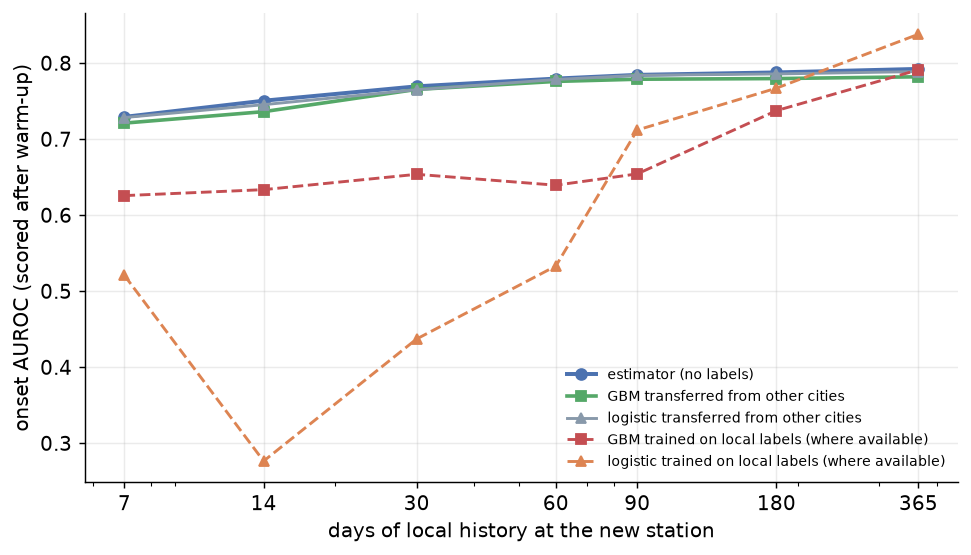

In [5]:
fig,ax=plt.subplots(figsize=(7.6,4.4))
ax.plot(R.days,R.est,"-o",color="#4C72B0",lw=2.2,label="estimator (no labels)")
ax.plot(R.days,R.loco_gbm,"-s",color="#55A868",lw=2,label="GBM transferred from other cities")
ax.plot(R.days,R.loco_log,"-^",color="#8899AA",lw=1.6,label="logistic transferred from other cities")
ax.plot(R.days,R.local_gbm,"--s",color="#C44E52",lw=1.6,label="GBM trained on local labels (where available)")
ax.plot(R.days,R.local_log,"--^",color="#DD8452",lw=1.6,label="logistic trained on local labels (where available)")
ax.set_xscale("log"); ax.set_xticks(R.days); ax.set_xticklabels(R.days)
ax.set_xlabel("days of local history at the new station"); ax.set_ylabel("onset AUROC (scored after warm-up)")
ax.legend(frameon=False,fontsize=8); plt.tight_layout(); plt.savefig(OUT/"s21_fig1_new_station.png",bbox_inches="tight"); plt.show()


## Station-level bootstrap for the estimator minus transferred GBM

The intervals above resample prediction points. Points from one station are serially dependent and share one set of
warm-up statistics, so treating them as independent gives intervals that are too narrow (the manuscript says so in
the Limitations). Here whole stations are resampled with replacement (2000 resamples, 21 stations), which keeps that
dependence inside each draw. The point estimates are unchanged; only the intervals differ. Cities (8) are too few
for a reliable cluster bootstrap, so stations are the resampling unit.

In [6]:
def station_boot(E,G,Y,S,n=2000,seed=1):
    sts=np.unique(S); idx={s:np.where(S==s)[0] for s in sts}; rng=np.random.default_rng(seed); d=[]
    for _ in range(n):
        pick=rng.choice(sts,len(sts),replace=True); i=np.concatenate([idx[s] for s in pick]); yi=Y[i]
        if 0<yi.sum()<len(yi): d.append(auc(E[i],yi)-auc(G[i],yi))
    lo,hi=np.percentile(d,[2.5,97.5]); return float(auc(E,Y)-auc(G,Y)),float(lo),float(hi),len(d)
rows=[]
for nd,k in KEEP.items():
    diff,lo,hi,nb_=station_boot(k["E"],k["G"],k["Y"],k["S"]); rr=R.set_index("days").loc[nd]
    rows.append(dict(days=nd,n_stations=len(np.unique(k["S"])),n_points=len(k["Y"]),est=auc(k["E"],k["Y"]),loco_gbm=auc(k["G"],k["Y"]),
                     diff=diff,point_lo95=rr.lo95,point_hi95=rr.hi95,station_lo95=lo,station_hi95=hi,n_boot=nb_))
    print(f"{nd:>4} d | est-GBM {diff:+.3f} | resampling points [{rr.lo95:+.3f},{rr.hi95:+.3f}] | resampling stations [{lo:+.3f},{hi:+.3f}]  ({nb_} resamples)")
CB=pd.DataFrame(rows); CB.to_csv(OUT/"s21_station_bootstrap.csv",index=False); print("saved",OUT/"s21_station_bootstrap.csv")

   7 d | est-GBM +0.008 | resampling points [+0.003,+0.014] | resampling stations [-0.019,+0.039]  (2000 resamples)
  14 d | est-GBM +0.014 | resampling points [+0.009,+0.021] | resampling stations [-0.011,+0.039]  (2000 resamples)
  30 d | est-GBM +0.004 | resampling points [-0.002,+0.010] | resampling stations [-0.011,+0.019]  (2000 resamples)
  60 d | est-GBM +0.004 | resampling points [-0.002,+0.010] | resampling stations [-0.013,+0.020]  (2000 resamples)
  90 d | est-GBM +0.006 | resampling points [+0.000,+0.012] | resampling stations [-0.009,+0.019]  (2000 resamples)
 180 d | est-GBM +0.008 | resampling points [+0.001,+0.014] | resampling stations [-0.006,+0.022]  (2000 resamples)
 365 d | est-GBM +0.010 | resampling points [+0.004,+0.018] | resampling stations [-0.001,+0.022]  (2000 resamples)
saved ../outputs/study21_new_station/s21_station_bootstrap.csv
